## Module Titile: Strategic Thinking

## Assignment Titile: CA 3 Final Submission

## Project Titile: Predicting Repeat Purchases in E-Commerce Using Interpretable Machine Learning



In [419]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier

In [420]:
# Load the dataset

df = pd.read_csv("Online_Retail.csv") 

## Data Understanding

#### Dataset Overview

In [421]:
# Preview the data

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

        InvoiceDate  UnitPrice  CustomerID         Country  
0  01/12/2010 08:26       2.55     17850.0  United Kingdom  
1  01/12/2010 08:26       3.39     17850.0  United Kingdom  
2  01/12/2010 08:26       2.75     17850.0  United Kingdom  
3  01/12/2010 08:26       3.39     17850.0  United Kingdom  
4  01/12/2010 08:26       3.39     17850.0  United Kingdom  


In [422]:
# Basic structure

print("Shape of dataset:", df.shape)
print("\nColumn names:\n", df.columns.tolist())

Shape of dataset: (541909, 8)

Column names:
 ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [423]:
# Data types and non-null counts

print("\nData info:")
df.info()


Data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [424]:
# Check missing values

print("\nMissing values per column:")

print(df.isnull().sum())


Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [425]:
# Unique values per column
print("\nUnique value counts per column:")

print(df.nunique().sort_values())


Unique value counts per column:
Country           38
Quantity         722
UnitPrice       1630
StockCode       4070
Description     4223
CustomerID      4372
InvoiceDate    23260
InvoiceNo      25900
dtype: int64


In [426]:
# Identify rows that are duplicated across all columns
duplicate_rows = df[df.duplicated(keep=False)]

# Display number of full duplicates
print(f"Number of fully duplicated rows: {duplicate_rows.shape[0]}")

# Preview the duplicated rows
print(duplicate_rows.head())

Number of fully duplicated rows: 10147
    InvoiceNo StockCode                       Description  Quantity  \
485    536409     22111      SCOTTIE DOG HOT WATER BOTTLE         1   
489    536409     22866     HAND WARMER SCOTTY DOG DESIGN         1   
494    536409     21866       UNION JACK FLAG LUGGAGE TAG         1   
517    536409     21866       UNION JACK FLAG LUGGAGE TAG         1   
521    536409     22900   SET 2 TEA TOWELS I LOVE LONDON          1   

          InvoiceDate  UnitPrice  CustomerID         Country  
485  01/12/2010 11:45       4.95     17908.0  United Kingdom  
489  01/12/2010 11:45       2.10     17908.0  United Kingdom  
494  01/12/2010 11:45       1.25     17908.0  United Kingdom  
517  01/12/2010 11:45       1.25     17908.0  United Kingdom  
521  01/12/2010 11:45       2.95     17908.0  United Kingdom  


In [427]:
print("\n Summary statistics for numeric columns:")

print(df[['Quantity', 'UnitPrice']].describe())


 Summary statistics for numeric columns:
            Quantity      UnitPrice
count  541909.000000  541909.000000
mean        9.552250       4.611114
std       218.081158      96.759853
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000


#### EDA (Exploratory Data Analysis)

##### Feature Distributions

Rationale: Understanding the distribution of numeric features helps identify skewness, modality, and outliers. This informs decisions about scaling, transformation, and filtering.

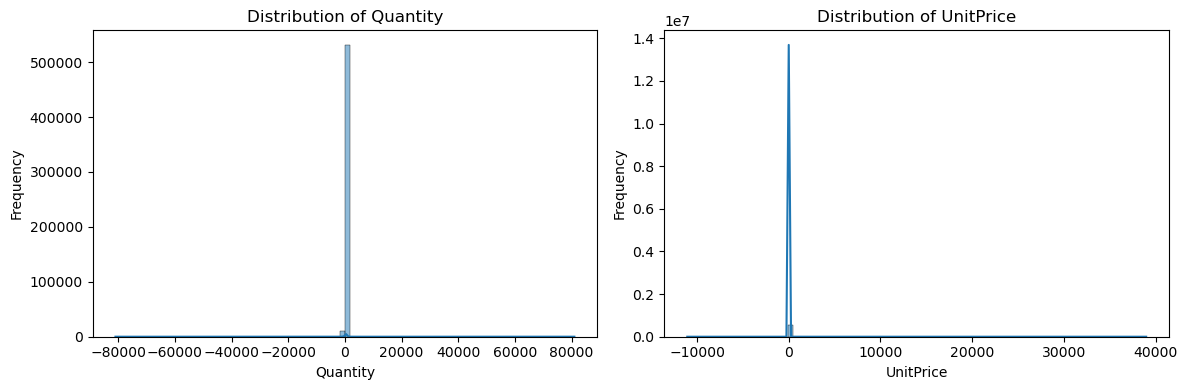

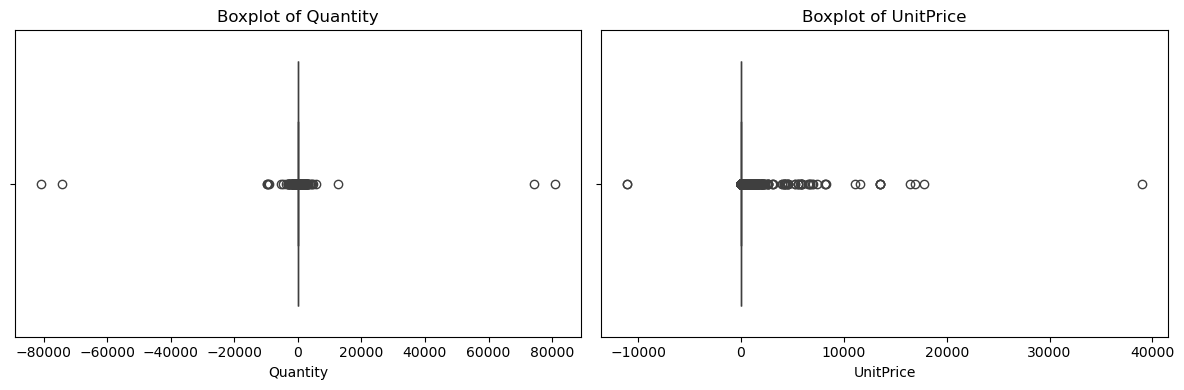

In [428]:
# Select numeric columns
numeric_cols = ['Quantity', 'UnitPrice']

# Histograms
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(1, len(numeric_cols), i+1)
    sns.histplot(df[col], bins=100, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Boxplots
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(1, len(numeric_cols), i+1)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

Rationale: Count plots reveal dominant categories, rare values, and potential encoding needs.

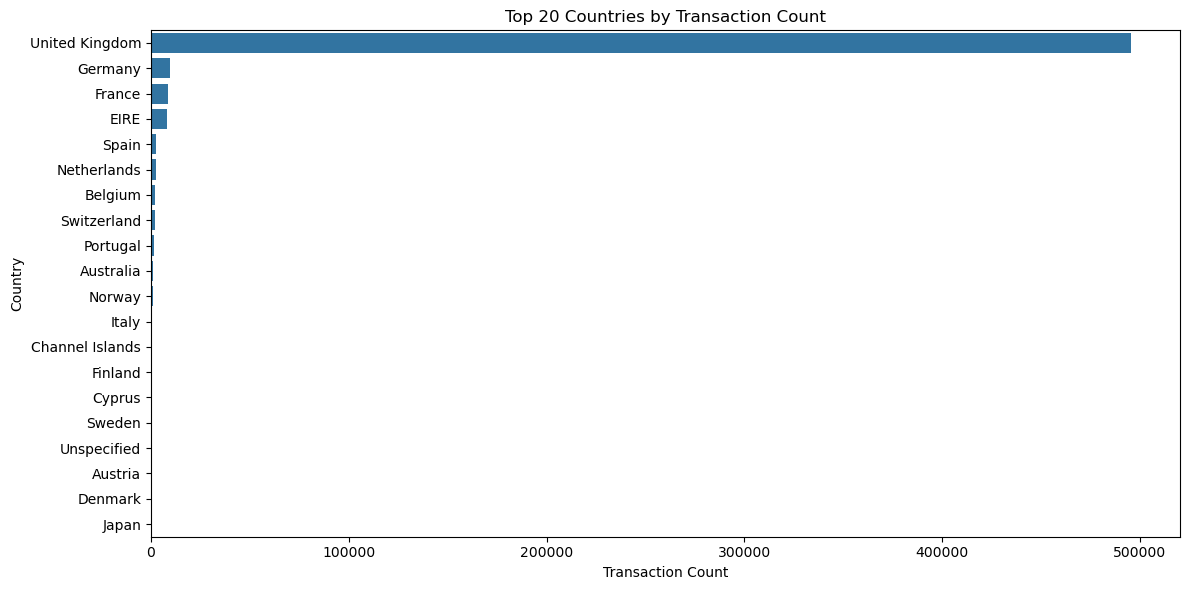

In [429]:
# Count plot for Country

top_countries = df['Country'].value_counts().head(20)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title('Top 20 Countries by Transaction Count')
plt.xlabel('Transaction Count')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


##### Correlation Matrix

Rationale: Identifies linear relationships between numeric features to guide feature selection and multicollinearity checks.

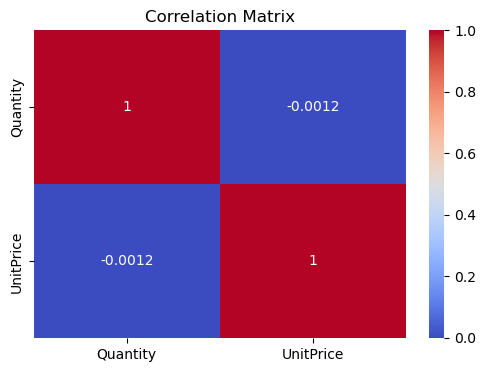

In [430]:
# Correlation matrix
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Quantity', 'UnitPrice']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

##### Outlier Detection

Rationale: Quantifies extreme values to inform filtering or transformation decisions.

In [431]:
# IQR-based outlier detection for Quantity and UnitPrice
numeric_features = ['Quantity', 'UnitPrice']

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f" Number of outliers in {col}: {outliers.shape[0]}")


 Number of outliers in Quantity: 58619
 Number of outliers in UnitPrice: 39627


##### Analyze Skewness of Numeric Features

Rationake: Skewness helps identify features with asymmetric distributions, which may benefit from transformation (e.g., log) to improve model performance and meet algorithm assumptions.

In [432]:
# Check skewness for numeric features
df[numeric_features].skew().sort_values(ascending=False)


UnitPrice    186.506972
Quantity      -0.264076
dtype: float64

##### Initial Hypotheses for Feature Engineering

Based on business intuition and exploratory analysis, the following hypotheses will guide feature creation:

1. Customers with higher **purchase frequency** (`transactions_per_customer`) are more likely to repeat purchases.  

2. Customers with higher **total spend** (`total_spend_per_customer`) are more likely to repeat purchases

3. **Shorter time gaps** (`avg_days_between_purchases`) between purchases increase repeat likelihood.

These features will be engineered and later interpreted using LIME to assess their influence on repeat purchase predictions.


## Data Preparation

In [433]:
# Drop rows with missing CustomerID (essential for customer-level features)
df = df.dropna(subset=['CustomerID'])

In [434]:
# Convert CustomerID to integer
df['CustomerID'] = df['CustomerID'].astype(int)

In [435]:
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)

In [436]:
# Remove negative or zero UnitPrice and Quantity (invalid transactions or returns)
df = df[(df['UnitPrice'] > 0) & (df['Quantity'] > 0)]

In [ ]:
# Outlier Removal Using IQR

def remove_all_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column] >= lower) & (df[column] <= upper)]
    return df

# Apply to both columns
df = remove_all_outliers_iqr(df, 'Quantity')
df = remove_all_outliers_iqr(df, 'UnitPrice')

In [438]:
# IQR-based outlier detection for Quantity and UnitPrice
numeric_cols = ['Quantity', 'UnitPrice']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f" Number of outliers in {col}: {outliers.shape[0]}")

 Number of outliers in Quantity: 0
 Number of outliers in UnitPrice: 15416


In [439]:
# Apply Log Transformation

df['Quantity'] = np.log1p(np.abs(df['Quantity']))
df['UnitPrice'] = np.log1p(np.abs(df['UnitPrice']))

In [440]:
# Check skewness for numeric features
df[numeric_cols].skew().sort_values(ascending=False)

UnitPrice    0.235794
Quantity     0.094012
dtype: float64

In [441]:
# Remove full duplicates
df = df.drop_duplicates()

In [442]:
# Create TotalSpend per row
df['TotalSpend'] = abs(df['Quantity']) * abs(df['UnitPrice'])

In [443]:
# Encode Country using one-hot encoding
df = pd.get_dummies(df, columns=['Country'], drop_first=True)


#### Feature Engineering

In [444]:
# Purchase frequency: transactions per customer
transactions_per_customer = df.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
transactions_per_customer.columns = ['CustomerID', 'transactions_per_customer']

In [445]:
# Total spend: total spend per customer
total_spend_per_customer = df.groupby('CustomerID')['TotalSpend'].sum().reset_index()
total_spend_per_customer.columns = ['CustomerID', 'total_spend_per_customer']

In [446]:
# Time gaps: average days between purchases
df_sorted = df.sort_values(by=['CustomerID', 'InvoiceDate'])
df_sorted['prev_date'] = df_sorted.groupby('CustomerID')['InvoiceDate'].shift(1)
df_sorted['days_between'] = (df_sorted['InvoiceDate'] - df_sorted['prev_date']).dt.days
avg_days_between = df_sorted.groupby('CustomerID')['days_between'].mean().reset_index()
avg_days_between.columns = ['CustomerID', 'avg_days_between_purchases']

In [447]:
# Recency: days since last purchase
last_purchase = df.groupby('CustomerID')['InvoiceDate'].max().reset_index()
last_purchase['recency_days'] = (df['InvoiceDate'].max() - last_purchase['InvoiceDate']).dt.days
last_purchase = last_purchase[['CustomerID', 'recency_days']]

In [448]:
# Product diversity: number of unique products purchased
product_diversity = df.groupby('CustomerID')['StockCode'].nunique().reset_index()
product_diversity.columns = ['CustomerID', 'unique_products_purchased']

In [449]:
# Initialize customer-level dataset with purchase frequency
df_customer = transactions_per_customer.copy()

In [450]:
# Merge other customer-level features one by one
df_customer = pd.merge(df_customer, total_spend_per_customer, on='CustomerID', how='left')
df_customer = pd.merge(df_customer, avg_days_between, on='CustomerID', how='left')
df_customer = pd.merge(df_customer, last_purchase, on='CustomerID', how='left')
df_customer = pd.merge(df_customer, product_diversity, on='CustomerID', how='left')

In [451]:
# Reference date for calculations
today = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Time Since First Purchase
first_purchase = df.groupby('CustomerID')['InvoiceDate'].min()
df_customer['time_since_first_purchase'] = df_customer['CustomerID'].map(lambda x: (today - first_purchase.get(x, today)).days)

In [452]:
# Average Order Value (AOV)

# Merge to compute AOV
df_aov = transactions_per_customer.merge(total_spend_per_customer, on='CustomerID')

# Calculate AOV
df_aov['average_order_value'] = df_aov['total_spend_per_customer'] / df_aov['transactions_per_customer']

# Merge AOV into df_customer
df_customer = df_customer.merge(df_aov[['CustomerID', 'average_order_value']], on='CustomerID', how='left')


In [453]:
# Purchase Frequency (Last 90 Days)
cutoff_90 = today - pd.Timedelta(days=90)
recent_transactions = df[df['InvoiceDate'] >= cutoff_90]
recent_freq = recent_transactions.groupby('CustomerID')['InvoiceNo'].nunique()
df_customer['purchase_freq_90d'] = df_customer['CustomerID'].map(recent_freq).fillna(0)

In [454]:
# Category Diversity
category_diversity = df.groupby('CustomerID')['Description'].nunique()
df_customer['category_diversity'] = df_customer['CustomerID'].map(category_diversity).fillna(0)

In [455]:
# Check missing values

print("\nMissing values per column:")

print(df_customer.isnull().sum())


Missing values per column:
CustomerID                     0
transactions_per_customer      0
total_spend_per_customer       0
avg_days_between_purchases    62
recency_days                   0
unique_products_purchased      0
time_since_first_purchase      0
average_order_value            0
purchase_freq_90d              0
category_diversity             0
dtype: int64


In [456]:
# Drop rows with missing values in 'avg_days_between_purchases'
df_customer.dropna(subset=['avg_days_between_purchases'], inplace=True)

##### Target Variable Creation

In [457]:
# Define repeat purchase: customers with more than one transaction
df_customer['repeat_purchase'] = df_customer['transactions_per_customer'].apply(lambda x: 1 if x > 1 else 0)

# Final feature set for modeling
X = df_customer.drop(['CustomerID', 'repeat_purchase'], axis=1)
y = df_customer['repeat_purchase']

##### Check Target Distribution

In [458]:
# Check class balance
print("Class counts:")
print(df_customer['repeat_purchase'].value_counts())
print("\nClass proportions:")
print(df_customer['repeat_purchase'].value_counts(normalize=True))


Class counts:
repeat_purchase
1    2704
0    1425
Name: count, dtype: int64

Class proportions:
repeat_purchase
1    0.65488
0    0.34512
Name: proportion, dtype: float64


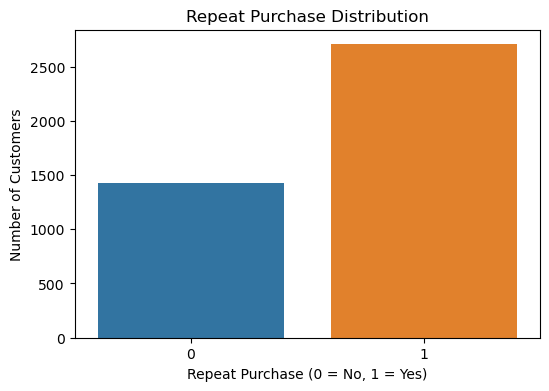

In [459]:
# Visualize the distribution of repeat vs non-repeat customers

plt.figure(figsize=(6, 4))
sns.countplot(x='repeat_purchase', data=df_customer, hue='repeat_purchase', legend=False)
plt.title('Repeat Purchase Distribution')
plt.xlabel('Repeat Purchase (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()


##### Explore Engineered Features Distributions

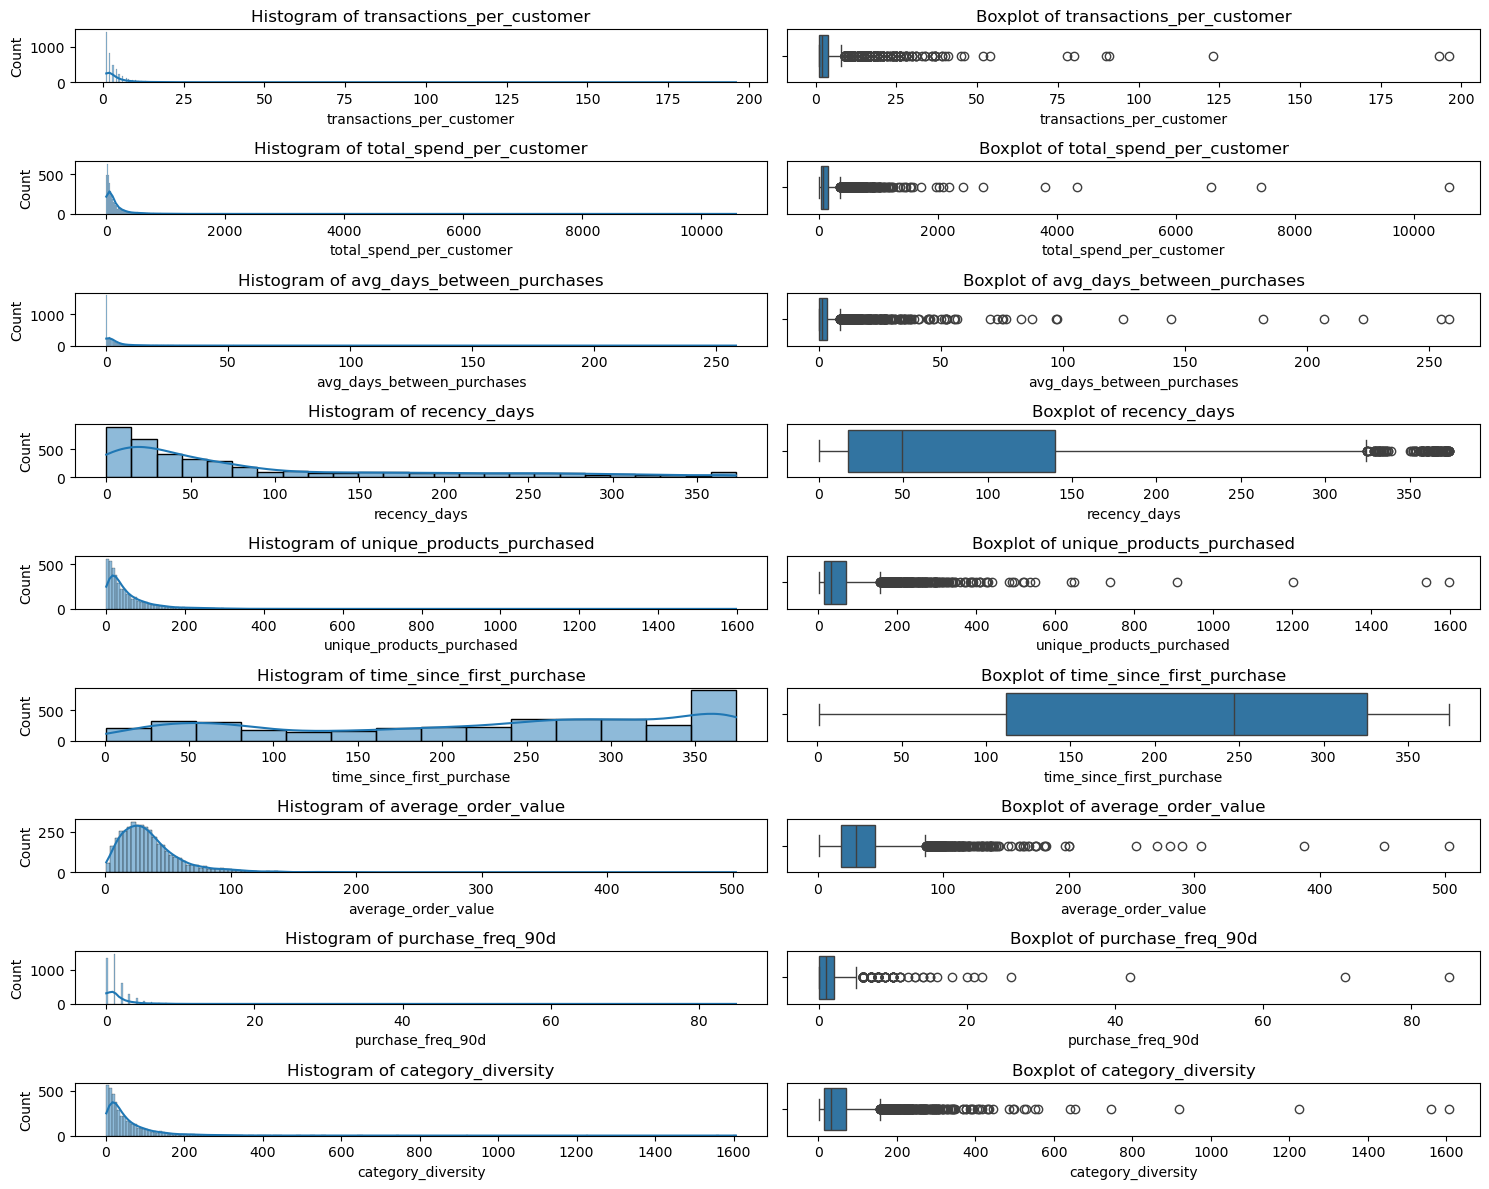

In [460]:
# Plot histograms and boxplots for numeric features to explore distributions and detect outliers


# Select numeric features excluding the target
numeric_cols = df_customer.select_dtypes(include=['int64', 'float64']).drop('repeat_purchase', axis=1).columns

# Set up plot grid
plt.figure(figsize=(15, 12))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 2, 2*i - 1)
    sns.histplot(df_customer[col], kde=True)
    plt.title(f'Histogram of {col}')

    plt.subplot(len(numeric_cols), 2, 2*i)
    sns.boxplot(x=df_customer[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

##### Apply IQR-Based Outlier Removal

In [ ]:
# Define function to iteratively remove IQR-based outliers

def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column] >= lower) & (df[column] <= upper)]

# Apply outlier removal to each engineered feature
for col in numeric_cols:
    df_customer = remove_all_outliers_iqr(df_customer, col)

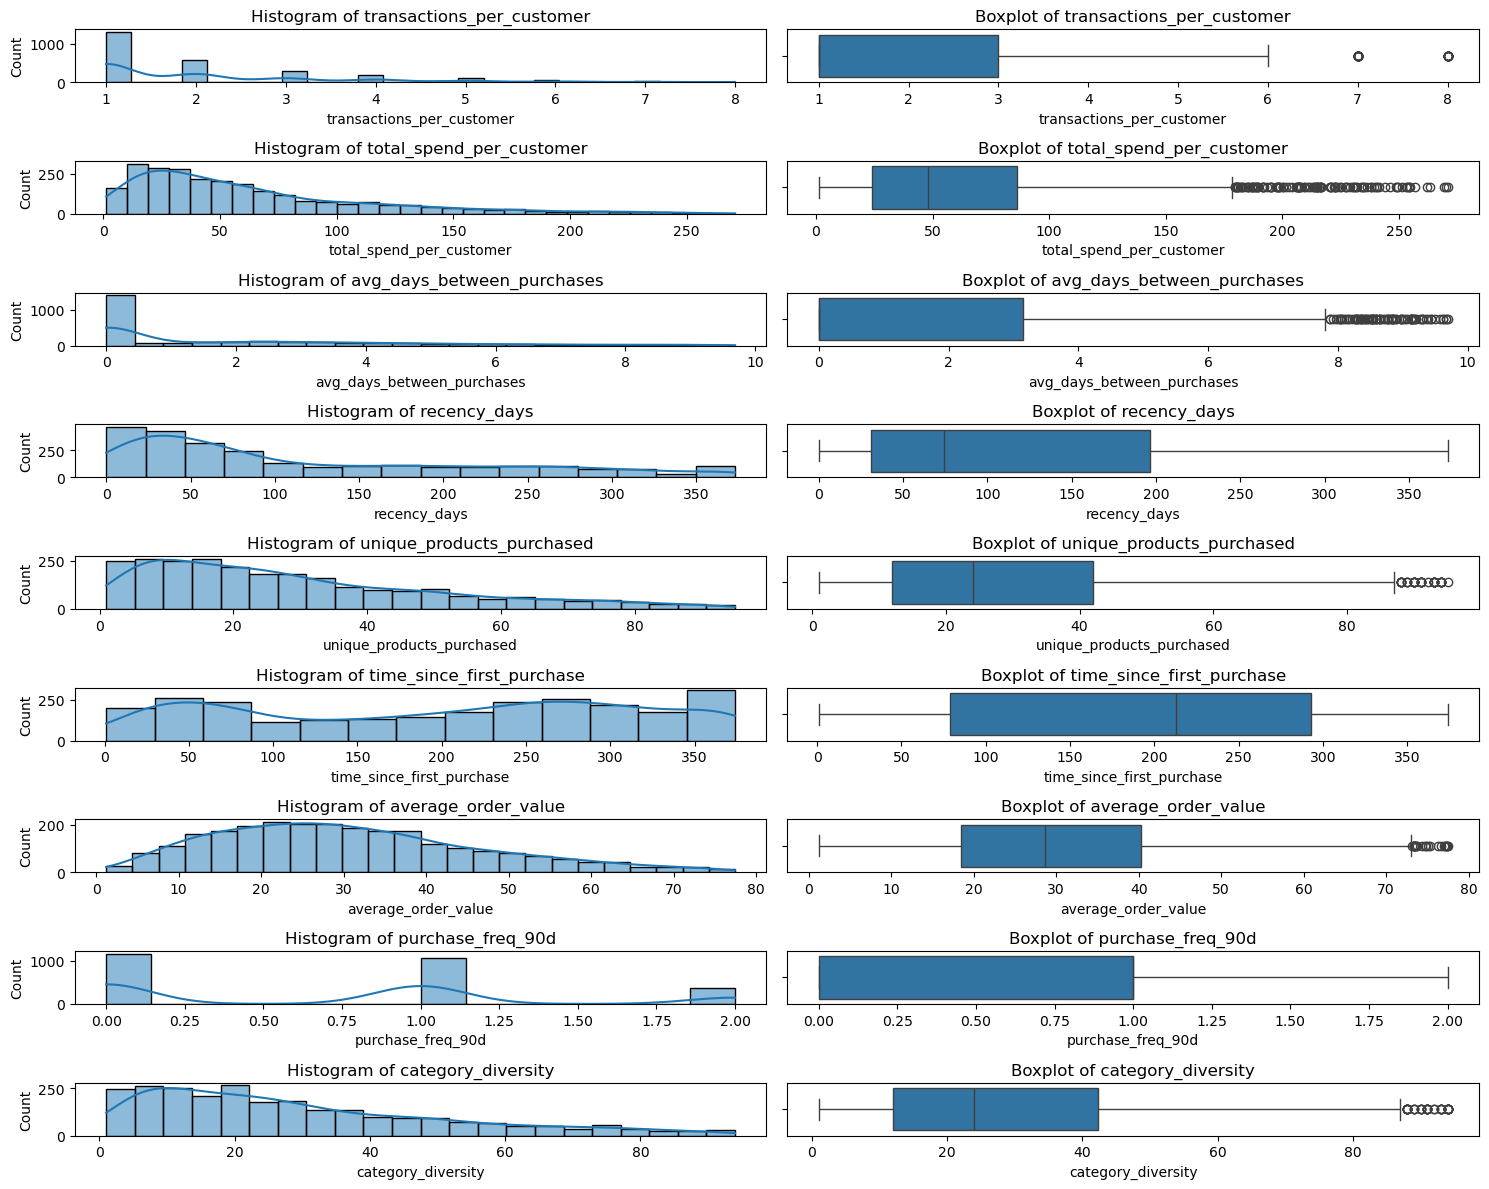

In [462]:
# Plot histograms and boxplots for numeric features to explore distributions and detect outliers


# Select numeric features excluding the target
numeric_cols = df_customer.select_dtypes(include=['int64', 'float64']).drop('repeat_purchase', axis=1).columns

# Set up plot grid
plt.figure(figsize=(15, 12))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 2, 2*i - 1)
    sns.histplot(df_customer[col], kde=True)
    plt.title(f'Histogram of {col}')

    plt.subplot(len(numeric_cols), 2, 2*i)
    sns.boxplot(x=df_customer[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

##### Analyze Skewness of Engineered Numeric Features

In [463]:
# Check skewness for engineered numeric features
df_customer[numeric_cols].skew().sort_values(ascending=False)

transactions_per_customer     1.635095
total_spend_per_customer      1.386466
avg_days_between_purchases    1.315850
unique_products_purchased     0.929452
category_diversity            0.928604
recency_days                  0.850482
average_order_value           0.584174
purchase_freq_90d             0.509390
time_since_first_purchase    -0.120567
dtype: float64

In [464]:
# Apply log transformation to reduce skewness in numeric features

for col in numeric_cols:
    df_customer[col] = np.log1p(df_customer[col])

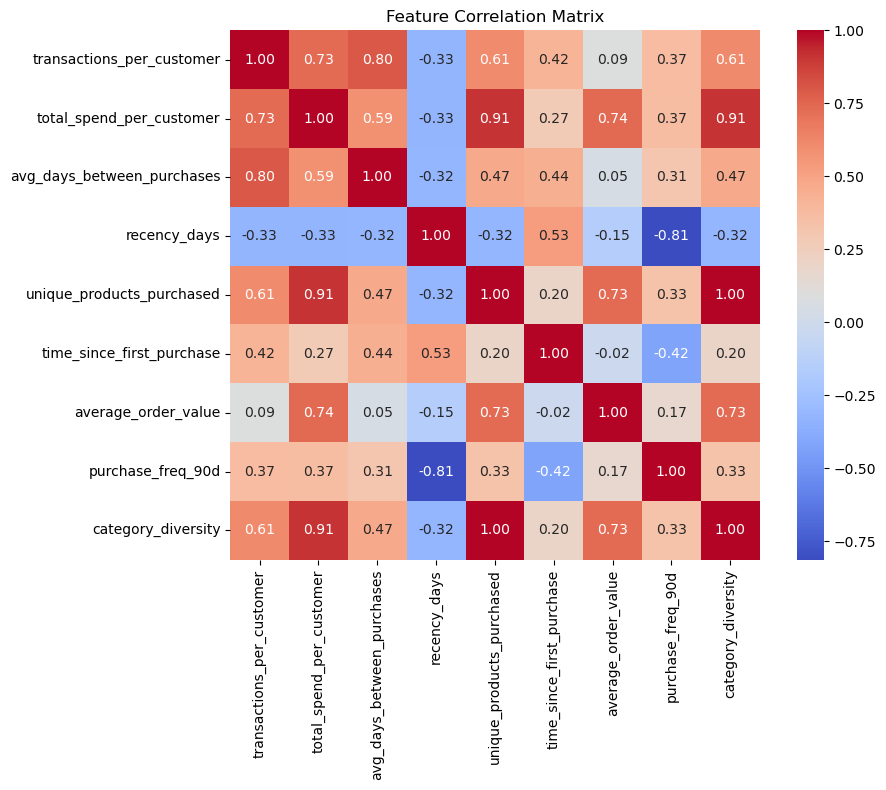

In [465]:
# Select only numeric features
features_only = df_customer.drop(columns=['CustomerID', 'repeat_purchase'])

# Compute correlation matrix
corr_matrix = features_only.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


In [466]:
# Compute mutual information scores
mi_scores = mutual_info_classif(X, y, discrete_features='auto')

# Display scores
mi_df = pd.DataFrame({'Feature': X.columns, 'MI Score': mi_scores})
mi_df = mi_df.sort_values(by='MI Score', ascending=False)
print(mi_df)

                      Feature  MI Score
0   transactions_per_customer  0.644494
2  avg_days_between_purchases  0.590843
1    total_spend_per_customer  0.233029
7           purchase_freq_90d  0.175864
4   unique_products_purchased  0.161377
8          category_diversity  0.160817
3                recency_days  0.128335
5   time_since_first_purchase  0.098477
6         average_order_value  0.004531


Rationale: Features are selected based on two criteria, one is High Mutual Information (MI) with the target variable to ensure predictive power and other low correlation with each other to reduce redundancy and multicollinearity
This selection balances signal strength and independence, making it suitable for both linear and tree-based models.


In [477]:
# Define the final list of selected features
selected_features = [     
    'avg_days_between_purchases',  
    'total_spend_per_customer', 
    'category_diversity',          
    'unique_products_purchased',
    'time_since_first_purchase'
]

##### Scale Features

In [478]:
# Select features and target

# selected features
X = df_customer[selected_features]
# Binary target variable
y = df_customer['repeat_purchase']

##### Train-Test Split with Stratification

In [479]:
# Train-test split with stratification to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [480]:
# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [481]:
# Apply SMOTE to balance the training set
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

##### Baseline Model

In [482]:
# Train a baseline Logistic Regression model
LR = LogisticRegression()
LR.fit(X_train_smote, y_train_smote)

LogisticRegression()

In [486]:
# Evaluate on the original test set
y_pred = LR.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98       262
           1       1.00      0.96      0.98       258

    accuracy                           0.98       520
   macro avg       0.98      0.98      0.98       520
weighted avg       0.98      0.98      0.98       520

